# 08 · Reconstruction, source covariance and residual risk

**Question:** which stages of our implemented transport pipeline change the
quality of short-history copper risk forecasts?

2016 is initial history; 2017–2025 is descriptive rolling evaluation. **2026 stays
held out and is never parsed or scored.** The current settlement is permitted;
older target prices are masked before every transformation. Raw counts are
preserved, documented counting conventions have an explicit normalized view,
and unknown declarations are not guessed.
The 2026 holdout concerns observation dates, not delivery months: 2025 quotes
for 2026-delivery contracts are contemporaneously known and remain eligible.

More calendar years add regimes and origins, not longer lives for individual
contracts. Even all-available current-triad history is limited by listings and
overlap inside the 252-interval window.

This notebook reads checksummed aggregate evidence only. It estimates policy
effects, rather than causal percentages of unobserved true covariance error.
[Protocol](../docs/mechanism-attribution.md) · [Report](../experiments/results/copper-mechanisms/report.md)

## Findings before the implementation details

The contrasts below measure changes in implemented policies on inspected settlements. They do not partition an unobserved true covariance error into causal percentages.

**The practical bottleneck in these controls is the chosen curve representation and its residual-risk repair.** Replacing the source-C estimator with direct innovation H changes the primary spread score by much less than reconstructing raw movements or adding the residual corrections. A small source-policy gap neither proves that C is correctly estimated nor identifies the physical forcing operator.

- **Passing the matched maturity pool through three-mode reconstruction:** zero-history spread QLIKE changes by +7.4832, with descriptive 95% block range [1.175, 20.02] across 437 paired origins.
- **Replacing direct innovation H with source-C fitting, with full residual repair fixed:** zero-history spread QLIKE changes by -0.0005, with descriptive 95% block range [-0.0008303, -0.0001656] across 437 paired origins.
- **Adding correlated residuals and cross terms to source factors:** zero-history spread QLIKE changes by -1.9064, with descriptive 95% block range [-4.63, -0.5171] across 437 paired origins.
- **Adding the donor-excluded diagonal correction:** zero-history spread QLIKE changes by -6.1102, with descriptive 95% block range [-16.89, -0.5667] across 437 paired origins.

Negative changes favor the positive-weight or added policy. Compare the full six cells and interaction contrasts before interpreting a single addition as a general improvement. Availability, annual strata and the one-day control remain part of the evidence.
These matched interventions do not telescope into the entire SPDE-minus-raw-pool performance gap: historical maturity-slot mapping and own-history blending differ from evaluating the current actual contracts at their future maturities. They remain additional policy choices rather than errors uniquely assigned to one of these three stages.

The matched one-day source-C minus direct-H spread difference is -0.000013, with block range [-8.329e-05, 8.163e-05]. This controls interval-length mixing while retaining the source estimator's regularization and constraints.

At zero own history, three-mode reconstruction retains 95.7% of outright, 12.4% of spread and 6.5% of butterfly training second moments in the matched pooling control. These are ratios of mean window moments, rather than shares of true latent risk or out-of-sample calibration.

Full residual repair gives source-C spread QLIKE 14.542, versus raw pooling 15.016; their hedge RMS levels are CNY 923.4 and 898.2. These descriptive levels illustrate that a better risk score need not imply a lower realized hedge RMS; they are not an additional paired significance test.

Correlated residuals alone are not a universal repair: at zero own history the source model's butterfly QLIKE changes from 34.752 to 39.010, and hedge RMS from CNY 1153.2 to 1396.7, despite the improved spread QLIKE. Evaluate all exposures and the diagonal addition separately.

The 2022 diagonal-repair spread contrast is -44.478, a particularly large annual effect. QLIKE means are sensitive to severe underprediction on stress observations; the large pooled effects and wide block ranges should not be read as equal improvement across regimes or as proof of erroneous source quotes.

Annual results are essential: large correction effects and wide block ranges can be concentrated in particular years. The pooled mean is not a claim of equal improvement in every market regime.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from spde_covariance.empirical_mechanisms import load_mechanism_evidence

evidence = load_mechanism_evidence(Path("../experiments/results/copper-mechanisms"))
METHOD_LABELS = {
    "source_factor": "Source C · factor",
    "source_correlated": "Source C · correlated",
    "source_diagonal": "Source C · diagonal",
    "empirical_factor": "Direct H · factor",
    "empirical_correlated": "Direct H · correlated",
    "empirical_diagonal": "Direct H · diagonal",
    "reconstructed_pool": "Reconstructed pool",
    "pooled_shrink": "Raw maturity pool",
    "direct": "Same-contract direct",
}
CELLS = (
    "source_factor",
    "source_correlated",
    "source_diagonal",
    "empirical_factor",
    "empirical_correlated",
    "empirical_diagonal",
)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def display(value):
    if value is None:
        return "Unavailable"
    if isinstance(value, (list, tuple)):
        return "[" + ", ".join(display(x) for x in value) + "]"
    if isinstance(value, float):
        return f"{value:,.4g}"
    return METHOD_LABELS.get(str(value), str(value))


def table(rows, columns):
    return "\n".join(
        [
            "| " + " | ".join(label for _, label in columns) + " |",
            "| " + " | ".join("---" for _ in columns) + " |",
            *(
                "| " + " | ".join(display(row.get(key)) for key, _ in columns) + " |"
                for row in rows
            ),
        ]
    )


def base_config(evidence):
    return evidence["protocol"]["config"]["base"]


def budgets(evidence):
    return [
        "all" if value is None else str(value) for value in base_config(evidence)["history_budgets"]
    ]


def select_summary(evidence, *, context="all", dimension=3, year="all", tenor="all"):
    return [
        row
        for row in evidence["summary"]["rows"]
        if row["context"] == context
        and row["dimension"] == dimension
        and row["year"] == str(year)
        and row["target_tenor_days"] == str(tenor)
    ]


def select_pairs(
    evidence, *, contrast, context="all", dimension=3, year="all", exposure="spread", policy=None
):
    return [
        row
        for row in evidence["paired"]["rows"]
        if row["contrast"] == contrast
        and row["context"] == context
        and row["dimension"] == dimension
        and row["year"] == str(year)
        and row["exposure"] == exposure
        and (policy is None or row["policy"] == policy)
    ]


def bounds(row, block):
    values = [item["percentile_95"] for item in row["bootstrap"] if item["block_origins"] == block]
    return values[0] if values and len(values[0]) == 2 else None


def _point(ax, x, row, block, *, color, label=None):
    interval = bounds(row, block)
    if interval is not None:
        ax.plot([x, x], interval, color=color, lw=1.2)
    ax.plot(x, row["difference"], "o", color=color, ms=4, label=label)


def plot_six_cells(evidence):
    history = budgets(evidence)
    shown = [history[0], history[-1]] if len(history) > 1 else history
    fig, axes = plt.subplots(2, len(shown), figsize=(6 * len(shown), 7), squeeze=False)
    rows = select_summary(evidence)
    colors = ("#d95f02", "#1f77b4")
    for column, budget in enumerate(shown):
        lookup = {row["method"]: row for row in rows if row["history_budget"] == budget}
        for row_index, exposure in enumerate(("spread", "butterfly")):
            ax = axes[row_index, column]
            for index, (prefix, color) in enumerate(
                zip(("source", "empirical"), colors, strict=True)
            ):
                values = [
                    lookup.get(prefix + "_" + correction, {})
                    .get("metrics", {})
                    .get(exposure, {})
                    .get("qlike", np.nan)
                    for correction in ("factor", "correlated", "diagonal")
                ]
                ax.plot(
                    range(3),
                    values,
                    "s--" if index == 0 else "o-",
                    color=color,
                    ms=6 if index == 0 else 4,
                    label="Source C" if index == 0 else "Direct H",
                )
            ax.set(
                title=f"{exposure.title()} · own history {budget}",
                xticks=range(3),
                xticklabels=["Factor", "+ correlated", "+ diagonal"],
                ylabel="QLIKE (lower is better)",
            )
            ax.grid(axis="y", alpha=0.2)
    axes[0, 0].legend(frameon=False)
    fig.suptitle("Three-mode representation: covariance policy crossed with residual corrections")
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    return fig


def plot_stage_contrasts(evidence):
    history, block = budgets(evidence), base_config(evidence)["bootstrap_block"]
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
    settings = (
        ("reconstruction_pool", "fixed_selectors", "Reconstructed − raw pool"),
        ("source_policy", "diagonal", "Source C − direct H; full residual"),
        ("residual_diagonal", "source", "Add diagonal to source + correlated"),
    )
    for ax, (contrast, policy, title) in zip(axes, settings, strict=True):
        ax.axhline(0, color=".6", lw=1)
        for j, (dimension, color) in enumerate(
            zip((2, 3, 4), ("#228833", "#1f77b4", "#d95f02"), strict=True)
        ):
            rows = select_pairs(evidence, contrast=contrast, policy=policy, dimension=dimension)
            for k, row in enumerate(rows):
                _point(
                    ax,
                    history.index(row["history_budget"]) + 0.16 * (j - 1),
                    row,
                    block,
                    color=color,
                    label=f"{dimension} modes" if k == 0 else None,
                )
        ax.set(
            title=title,
            xticks=range(len(history)),
            xticklabels=history,
            xlabel="Permitted own changes",
            ylabel="Paired spread QLIKE difference",
        )
        ax.grid(axis="y", alpha=0.2)
    axes[0].legend(frameon=False)
    fig.suptitle("Matched stage contrasts: negative favors the added or positive-weight policy")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    return fig


def plot_calendar_context(evidence):
    years = sorted({row["year"] for row in evidence["paired"]["rows"] if row["year"] != "all"})
    block = base_config(evidence)["bootstrap_block"]
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
    for ax, contrast, policy, title in (
        (axes[0], "source_policy", "diagonal", "Source C − direct H, full residual"),
        (axes[1], "residual_diagonal", "source", "Add diagonal to source + correlated"),
    ):
        ax.axhline(0, color=".6", lw=1)
        for j, (context, color, label) in enumerate(
            (
                ("all", "#1f77b4", "All intervals"),
                ("one_day", "#d95f02", "Matched one-day"),
            )
        ):
            for k, year in enumerate(years):
                candidates = [
                    row
                    for row in select_pairs(
                        evidence, contrast=contrast, policy=policy, context=context, year=year
                    )
                    if row["history_budget"] == "0"
                ]
                if candidates:
                    _point(
                        ax,
                        k + 0.09 * (2 * j - 1),
                        candidates[0],
                        block,
                        color=color,
                        label=label if k == 0 else None,
                    )
        ax.set(
            title=title,
            xticks=range(len(years)),
            xticklabels=years,
            ylabel="Paired spread QLIKE difference",
            xlabel="Calendar year; zero own history",
        )
        ax.tick_params(axis="x", rotation=45)
        ax.grid(axis="y", alpha=0.2)
    axes[0].legend(frameon=False)
    fig.suptitle("Annual and interval-context checks; fixed three-mode reconstruction")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    return fig


def plot_calibration(evidence):
    history = budgets(evidence)
    fig, axes = plt.subplots(1, 3, figsize=(12.5, 4))
    settings = (
        (0, "pooled_shrink", "Raw pool", "#555555"),
        (3, "reconstructed_pool", "Reconstructed pool", "#228833"),
        (3, "source_diagonal", "Source C + full residual", "#d95f02"),
        (3, "empirical_diagonal", "Direct H + full residual", "#1f77b4"),
    )
    for ax, exposure in zip(axes, ("outright", "spread", "butterfly"), strict=True):
        ax.axhline(1, color=".5", lw=1)
        for dimension, method, label, color in settings:
            rows = {
                row["history_budget"]: row
                for row in select_summary(evidence, dimension=dimension)
                if row["method"] == method
            }
            values = [
                rows.get(budget, {})
                .get("metrics", {})
                .get(exposure, {})
                .get("calibration_ratio", np.nan)
                for budget in history
            ]
            ax.plot(
                range(len(history)),
                values,
                "s--" if method == "source_diagonal" else "o-",
                color=color,
                ms=6 if method == "source_diagonal" else 4,
                label=label,
            )
        ax.set(
            title=exposure.title(),
            xticks=range(len(history)),
            xticklabels=history,
            xlabel="Permitted own changes",
            yscale="log",
        )
        ax.grid(axis="y", alpha=0.2)
    axes[0].set_ylabel("Forecast / realized second moment (log)")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
    fig.suptitle("Calibration after each policy change; one denotes aggregate calibration")
    fig.tight_layout(rect=(0, 0.16, 1, 0.94))
    return fig


def policy_table(evidence, *, context="all", dimension=3):
    output = []
    for row in select_summary(evidence, context=context, dimension=dimension):
        metrics = row["metrics"]
        output.append(
            {
                "budget": row["history_budget"],
                "method": row["method"],
                "scored": f"{row['scored']}/{row['episodes']}",
                "origins": row["origins"],
                "outright": metrics.get("outright", {}).get("qlike"),
                "spread": metrics.get("spread", {}).get("qlike"),
                "butterfly": metrics.get("butterfly", {}).get("qlike"),
                "calibration": metrics.get("spread", {}).get("calibration_ratio"),
                "rms": metrics.get("hedge", {}).get("realized_rms_cny"),
                "joint": metrics.get("joint", {}).get("quadratic") / 1e12
                if metrics.get("joint", {}).get("quadratic") is not None
                else None,
            }
        )
    methods = ("direct", "pooled_shrink", *CELLS, "reconstructed_pool")
    return sorted(
        output,
        key=lambda row: (budgets(evidence).index(row["budget"]), methods.index(row["method"])),
    )


def contrast_table(evidence, *, contrast, policy=None, context="all", exposure="spread"):
    output, block = [], base_config(evidence)["bootstrap_block"]
    for dimension in evidence["protocol"]["config"]["dimensions"]:
        for row in select_pairs(
            evidence,
            contrast=contrast,
            policy=policy,
            context=context,
            dimension=dimension,
            exposure=exposure,
        ):
            output.append(
                {
                    "dimension": dimension,
                    "budget": row["history_budget"],
                    "policy": row["policy"],
                    "difference": row["difference"],
                    "range": bounds(row, block),
                    "origins": row["paired_origins"],
                }
            )
    return sorted(
        output,
        key=lambda row: (
            evidence["protocol"]["config"]["dimensions"].index(row["dimension"]),
            budgets(evidence).index(row["budget"]),
            row["policy"],
        ),
    )


def findings_text(evidence):
    lines = [
        "The contrasts below measure changes in implemented policies on inspected settlements. They do not partition an unobserved true covariance error into causal percentages.",
        "",
    ]
    block = base_config(evidence)["bootstrap_block"]
    primary_source = [
        row
        for row in select_pairs(evidence, contrast="source_policy", policy="diagonal")
        if row["history_budget"] == "0"
    ]
    reconstruction = [
        row
        for row in select_pairs(evidence, contrast="reconstruction_pool", policy="fixed_selectors")
        if row["history_budget"] == "0"
    ]
    if (
        primary_source
        and reconstruction
        and abs(primary_source[0]["difference"]) < 0.01 * abs(reconstruction[0]["difference"])
    ):
        lines += [
            "**The practical bottleneck in these controls is the chosen curve representation and its residual-risk repair.** Replacing the source-C estimator with direct innovation H changes the primary spread score by much less than reconstructing raw movements or adding the residual corrections. A small source-policy gap neither proves that C is correctly estimated nor identifies the physical forcing operator.",
            "",
        ]
    for contrast, policy, label in (
        (
            "reconstruction_pool",
            "fixed_selectors",
            "Passing the matched maturity pool through three-mode reconstruction",
        ),
        (
            "source_policy",
            "diagonal",
            "Replacing direct innovation H with source-C fitting, with full residual repair fixed",
        ),
        (
            "residual_correlated",
            "source",
            "Adding correlated residuals and cross terms to source factors",
        ),
        ("residual_diagonal", "source", "Adding the donor-excluded diagonal correction"),
    ):
        rows = [
            row
            for row in select_pairs(evidence, contrast=contrast, policy=policy)
            if row["history_budget"] == "0"
        ]
        if rows:
            row, interval = rows[0], bounds(rows[0], block)
            lines.append(
                f"- **{label}:** zero-history spread QLIKE changes by {row['difference']:+.4f}, with descriptive 95% block range {display(interval)} across {row['paired_origins']} paired origins."
            )
    lines += [
        "",
        "Negative changes favor the positive-weight or added policy. Compare the full six cells and interaction contrasts before interpreting a single addition as a general improvement. Availability, annual strata and the one-day control remain part of the evidence.",
        "These matched interventions do not telescope into the entire SPDE-minus-raw-pool performance gap: historical maturity-slot mapping and own-history blending differ from evaluating the current actual contracts at their future maturities. They remain additional policy choices rather than errors uniquely assigned to one of these three stages.",
    ]
    one_day = [
        row
        for row in select_pairs(
            evidence, contrast="source_policy", policy="diagonal", context="one_day"
        )
        if row["history_budget"] == "0"
    ]
    if one_day:
        row = one_day[0]
        lines += [
            "",
            f"The matched one-day source-C minus direct-H spread difference is {row['difference']:+.6f}, with block range {display(bounds(row, block))}. This controls interval-length mixing while retaining the source estimator's regularization and constraints.",
        ]
    retention, _ = diagnostic_tables(evidence)
    retained = {
        row["exposure"]: row["retention"]
        for row in retention
        if row["dimension"] == 3 and row["budget"] == "0"
    }
    if all(retained.get(name) is not None for name in ("outright", "spread", "butterfly")):
        lines += [
            "",
            f"At zero own history, three-mode reconstruction retains {retained['outright']:.1%} of outright, {retained['spread']:.1%} of spread and {retained['butterfly']:.1%} of butterfly training second moments in the matched pooling control. These are ratios of mean window moments, rather than shares of true latent risk or out-of-sample calibration.",
        ]
    rows = {row["method"]: row for row in select_summary(evidence) if row["history_budget"] == "0"}
    raw = {
        row["method"]: row
        for row in select_summary(evidence, dimension=0)
        if row["history_budget"] == "0"
    }
    if "source_diagonal" in rows and "pooled_shrink" in raw:
        repaired, pool = rows["source_diagonal"]["metrics"], raw["pooled_shrink"]["metrics"]
        lines += [
            "",
            f"Full residual repair gives source-C spread QLIKE {repaired['spread']['qlike']:.3f}, versus raw pooling {pool['spread']['qlike']:.3f}; their hedge RMS levels are CNY {repaired['hedge']['realized_rms_cny']:.1f} and {pool['hedge']['realized_rms_cny']:.1f}. These descriptive levels illustrate that a better risk score need not imply a lower realized hedge RMS; they are not an additional paired significance test.",
        ]
    if "source_correlated" in rows and "source_factor" in rows:
        correlated, factor = rows["source_correlated"]["metrics"], rows["source_factor"]["metrics"]
        lines += [
            "",
            f"Correlated residuals alone are not a universal repair: at zero own history the source model's butterfly QLIKE changes from {factor['butterfly']['qlike']:.3f} to {correlated['butterfly']['qlike']:.3f}, and hedge RMS from CNY {factor['hedge']['realized_rms_cny']:.1f} to {correlated['hedge']['realized_rms_cny']:.1f}, despite the improved spread QLIKE. Evaluate all exposures and the diagonal addition separately.",
        ]
    stress_2022 = [
        row
        for row in select_pairs(
            evidence, contrast="residual_diagonal", policy="source", year="2022"
        )
        if row["history_budget"] == "0"
    ]
    if stress_2022:
        lines += [
            "",
            f"The 2022 diagonal-repair spread contrast is {stress_2022[0]['difference']:+.3f}, a particularly large annual effect. QLIKE means are sensitive to severe underprediction on stress observations; the large pooled effects and wide block ranges should not be read as equal improvement across regimes or as proof of erroneous source quotes.",
        ]
    lines += [
        "",
        "Annual results are essential: large correction effects and wide block ranges can be concentrated in particular years. The pooled mean is not a claim of equal improvement in every market regime.",
    ]
    return "\n".join(lines)


def oracle_tables(evidence):
    oracle = evidence["oracle"]
    transport = [
        {
            "representation": row["representation"],
            "policy": row["covariance_policy"],
            "days": row["future_calendar_days"],
            "error": row["relative_kernel_error"]["mean"],
            "mcse": row["relative_kernel_error"]["mcse"],
        }
        for row in oracle["transport"]["rows"]
    ]
    residual = [
        {
            "policy": row["policy"],
            "error": row["relative_kernel_error"],
            "spread_ratio": row["risk_ratio"]["spread"],
            "butterfly_ratio": row["risk_ratio"]["butterfly"],
        }
        for row in oracle["residual"]["rows"]
    ]
    return transport, residual


def diagnostic_tables(evidence):
    """Expose reconstruction retention and optimization, without private rows."""
    retention, numerical = [], []
    for row in evidence["diagnostics"]["rows"]:
        numeric = row["numeric"]

        def value(key, statistic="mean"):
            item = numeric.get(key, {})
            return item.get(statistic)

        def maximum(key):
            values = value(key, "min_median_max")
            return values[-1] if values else None

        if row["context"] == "all" and row["method"] == "reconstructed_pool":
            for exposure in ("outright", "spread", "butterfly"):
                prefix = f"reconstruction_retention.{exposure}."
                raw = value(prefix + "raw_second_moment")
                retention.append(
                    {
                        "dimension": row["dimension"],
                        "budget": row["history_budget"],
                        "exposure": exposure,
                        "count": numeric.get(prefix + "raw_second_moment", {}).get("count", 0),
                        "retention": value(prefix + "fitted_second_moment") / raw
                        if raw and value(prefix + "fitted_second_moment") is not None
                        else None,
                        "residual": value(prefix + "residual_second_moment") / raw
                        if raw and value(prefix + "residual_second_moment") is not None
                        else None,
                        "cross": value(prefix + "signed_cross_second_moment") / raw
                        if raw and value(prefix + "signed_cross_second_moment") is not None
                        else None,
                        "identity": maximum("reconstruction_identity_relative_residual"),
                    }
                )
        if row["method"] == "source_diagonal" and row["history_budget"] in ("0", "all"):
            numerical.append(
                {
                    "dimension": row["dimension"],
                    "context": row["context"],
                    "budget": row["history_budget"],
                    "attempted": row["issued"],
                    "scored": row["scored"],
                    "certificate": maximum("source_fit.relative_covariance_error_bound"),
                    "condition": maximum("reconstruction.curve_condition_max"),
                    "leverage": maximum("reconstruction.level_fit_leverage_max"),
                    "support": maximum("relative_support_residual"),
                    "component": maximum("component_sum_relative_residual"),
                    "loo": value("leave_one_donor_out_annual_mse"),
                }
            )
    retention.sort(
        key=lambda row: (
            row["dimension"],
            budgets(evidence).index(row["budget"]),
            ("outright", "spread", "butterfly").index(row["exposure"]),
        )
    )
    numerical.sort(
        key=lambda row: (row["dimension"], row["context"], budgets(evidence).index(row["budget"]))
    )
    return retention, numerical


def data_audit_table(evidence):
    audit = evidence["manifest"].get("importer_audit") or {}
    return [
        {
            "year": row["year"],
            "sessions": row["sessions"],
            "rows": row["rows"],
            "missing": row["settlement_nonfinite"],
            "nonpositive": row["settlement_nonpositive"],
            "volume_zero": row["volume_zero"],
            "oi_zero": row["open_interest_zero"],
            "convention": ", ".join(row.get("volume_counting_conventions", [])),
            "unknown_sessions": row["normalization_unavailable_sessions"],
        }
        for row in audit.get("by_year", [])
    ]


def history_availability_table(evidence):
    output = [
        {
            "budget": row["history_budget"],
            "windows": row["issued"],
            "own_count": row["numeric"].get("complete_changes", {}).get("min_median_max"),
            "pooled_count": row["numeric"].get("pooled_changes", {}).get("min_median_max"),
        }
        for row in evidence["diagnostics"]["rows"]
        if row["context"] == "all" and row["dimension"] == 0 and row["method"] == "pooled_shrink"
    ]
    return sorted(output, key=lambda row: budgets(evidence).index(row["budget"]))


def maturity_table(evidence):
    output = []
    for tenor in base_config(evidence)["target_tenors_days"]:
        for dimension, method in (
            (0, "pooled_shrink"),
            (3, "source_diagonal"),
            (3, "empirical_diagonal"),
        ):
            for row in select_summary(evidence, dimension=dimension, tenor=tenor):
                if row["method"] == method and row["history_budget"] in ("0", "all"):
                    metrics = row["metrics"]
                    output.append(
                        {
                            "tenor": tenor,
                            "budget": row["history_budget"],
                            "method": method,
                            "scored": f"{row['scored']}/{row['episodes']}",
                            "outright": metrics.get("outright", {}).get("qlike"),
                            "spread": metrics.get("spread", {}).get("qlike"),
                            "butterfly": metrics.get("butterfly", {}).get("qlike"),
                            "calibration": metrics.get("spread", {}).get("calibration_ratio"),
                            "rms": metrics.get("hedge", {}).get("realized_rms_cny"),
                        }
                    )
    return sorted(
        output,
        key=lambda row: (
            row["tenor"],
            budgets(evidence).index(row["budget"]),
            ("pooled_shrink", "source_diagonal", "empirical_diagonal").index(row["method"]),
        ),
    )


print("Numerical source:", evidence["manifest"]["code_revision"])
print("Clean numerical source:", not evidence["manifest"]["source_dirty"])
print("Chronology:", evidence["protocol"]["chronology"])
print("Scheduled origins:", evidence["manifest"]["scheduled_origins"])
assert evidence["paired"]["joint_resampling"]
assert evidence["paired"]["one_day_missing_origins_retained"]
assert base_config(evidence)["test_end"] < "2026-01-01"

Numerical source: 68e3f17f4edc1c4230ad571e38ff7b06c7acd1c9
Clean numerical source: True
Chronology: 2016 warmup; 2017–2025 descriptive rolling evaluation; 2026 sealed reserve
Scheduled origins: 437


In [2]:
print(findings_text(evidence))
print(
    table(
        data_audit_table(evidence),
        [
            ("year", "Year"),
            ("sessions", "Sessions"),
            ("rows", "Copper rows"),
            ("missing", "Nonfinite settlements"),
            ("nonpositive", "Nonpositive settlements"),
            ("volume_zero", "Zero volume"),
            ("oi_zero", "Zero OI"),
            ("convention", "Count convention"),
            ("unknown_sessions", "Unknown-count sessions"),
        ],
    )
)
print(
    "Raw archived counts remain unchanged; unknown normalized views are unavailable, not guessed."
)
print(
    table(
        history_availability_table(evidence),
        [
            ("budget", "Own history"),
            ("windows", "Masked windows"),
            ("own_count", "Actual-triad complete changes: min/median/max"),
            ("pooled_count", "Pooled changes: min/median/max"),
        ],
    )
)

The contrasts below measure changes in implemented policies on inspected settlements. They do not partition an unobserved true covariance error into causal percentages.

**The practical bottleneck in these controls is the chosen curve representation and its residual-risk repair.** Replacing the source-C estimator with direct innovation H changes the primary spread score by much less than reconstructing raw movements or adding the residual corrections. A small source-policy gap neither proves that C is correctly estimated nor identifies the physical forcing operator.

- **Passing the matched maturity pool through three-mode reconstruction:** zero-history spread QLIKE changes by +7.4832, with descriptive 95% block range [1.175, 20.02] across 437 paired origins.
- **Replacing direct innovation H with source-C fitting, with full residual repair fixed:** zero-history spread QLIKE changes by -0.0005, with descriptive 95% block range [-0.0008303, -0.0001656] across 437 paired origins.
- **Add

## 1. A matched six-cell experiment

Hold fitted curves and innovations
$$z_i=(\widehat a_i-M_{\Delta_i}\widehat a_{i-1})/\sqrt{\Delta_i}$$
fixed. Compare source-C integration with direct EWMA innovation H. Cross both
with factor-only, correlated-residual/cross-term and added-diagonal forecasts.
The two main covariance forecasts are
$$\widehat H_D=\sum_iw_i z_i z_i^\top,\qquad
\widehat H_C(\delta)=\delta^{-1}\int_0^\delta M_u\widehat C M_u^\top\,du.$$
Row comparisons share exactly the same fitted residual statistics. Source-C
also imposes ridge and trace constraints, so its difference is a complete
source-estimation policy effect. A variance interpretation assumes negligible
conditional means. CNY risk uses the five-tonne multiplier squared.

| Own history | Policy | Scored / attempted | Outright QLIKE | Spread QLIKE | Butterfly QLIKE | Spread calibration | Joint quadratic / 10¹² CNY⁴ | Hedge RMS CNY |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | Source C · factor | 1311/1311 | 16.85 | 22.56 | 34.75 | 0.1102 | -173.1 | 1,153 |
| 0 | Source C · correlated | 1311/1311 | 16.85 | 20.65 | 39.01 | 0.1498 | -168.3 | 1,397 |
| 0 | Source C · diagonal | 1311/1311 | 16.85 | 14.54 | 15.97 | 1.076 | -123.1 | 923.4 |
| 0 | Direct H · factor | 1311/1311 | 16.85 | 22.56 | 34.8 | 0.1111 | -171.7 | 1,154 |
| 0 | Direct H · correlated | 1311/1311 | 16.85 | 20.67 | 39 | 0.1506 | -166.8 | 1,396 |
| 0 | Direct H · diagonal | 1311/1311 | 16.85 | 14.54 | 15.97 | 1.077 | -121.5 | 923.3 |
| 0 | Reconstructed pool | 1311/1311 | 16.85 | 22.5 | 34.92 | 0.1106 | -168.9 | 1,160 |
| 5 | Source C · factor | 1311/1311 | 16.85 | 22.48 | 34.69 | 0.1102 | -173.1 | 1,158 |
| 5 | Source C · correlated | 1311/1311 | 16.85 | 20.61 | 38.87 | 0.149

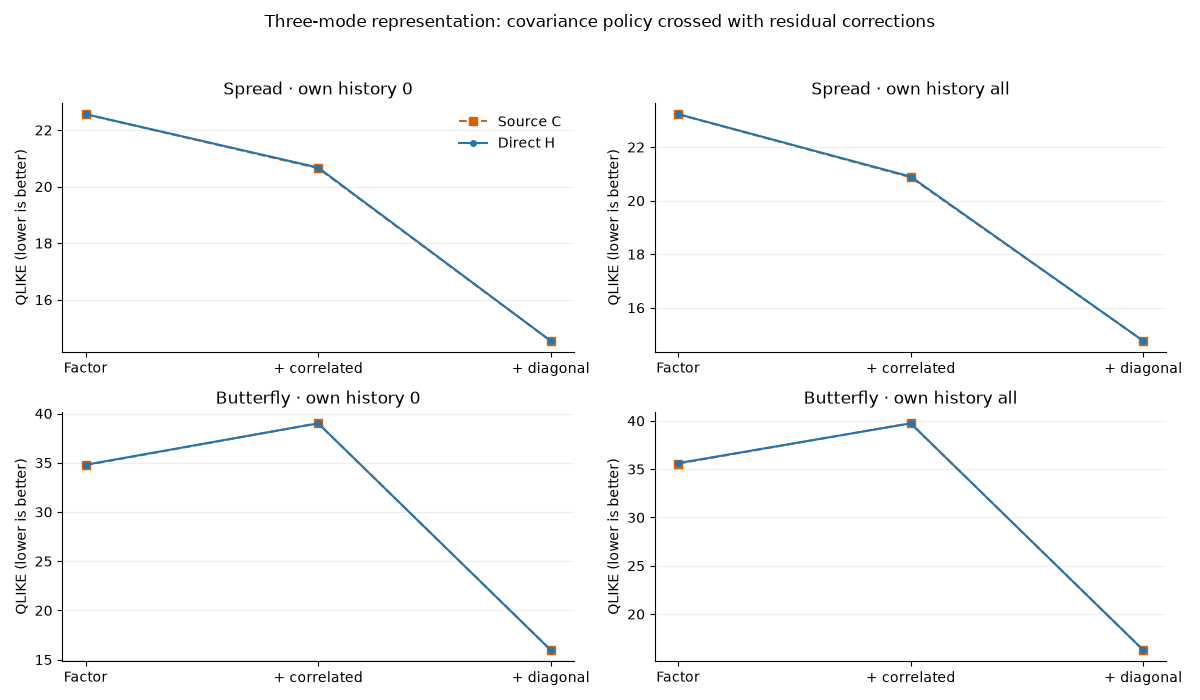

In [3]:
plot_six_cells(evidence)
plt.show()
rows = policy_table(evidence)
print(
    table(
        rows,
        [
            ("budget", "Own history"),
            ("method", "Policy"),
            ("scored", "Scored / attempted"),
            ("outright", "Outright QLIKE"),
            ("spread", "Spread QLIKE"),
            ("butterfly", "Butterfly QLIKE"),
            ("calibration", "Spread calibration"),
            ("joint", "Joint quadratic / 10¹² CNY⁴"),
            ("rms", "Hedge RMS CNY"),
        ],
    )
)
print("Raw-data baselines; direct unavailable below twenty complete changes:")
print(
    table(
        policy_table(evidence, dimension=0),
        [
            ("budget", "Own history"),
            ("method", "Policy"),
            ("scored", "Scored / attempted"),
            ("outright", "Outright QLIKE"),
            ("spread", "Spread QLIKE"),
            ("butterfly", "Butterfly QLIKE"),
            ("calibration", "Spread calibration"),
            ("joint", "Joint quadratic / 10¹² CNY⁴"),
            ("rms", "Hedge RMS CNY"),
        ],
    )
)
print("Maturity strata at zero/all available history:")
print(
    table(
        maturity_table(evidence),
        [
            ("tenor", "Target days"),
            ("budget", "History"),
            ("method", "Policy"),
            ("scored", "Scored / attempted"),
            ("outright", "Outright QLIKE"),
            ("spread", "Spread QLIKE"),
            ("butterfly", "Butterfly QLIKE"),
            ("calibration", "Spread calibration"),
            ("rms", "Hedge RMS CNY"),
        ],
    )
)
assert all(
    row["scored"] <= row["available"] <= row["episodes"] for row in evidence["summary"]["rows"]
)

## 2. Separate reconstruction from maturity selection

Raw and reconstructed pooling use identical historical actual IDs, intervals,
ages, own-triad counts and blend weights. Only price changes pass through the
curve fit. In this invariant finite basis, adjusted innovations evaluated at
end maturity equal fitted same-ID endpoint changes exactly. Retained spread and
butterfly movements, residuals and signed cross terms describe this filter.
Two- and four-mode sensitivity runs are fixed; they do not reveal continuum truth.
Historical own-triad fitted prices can extrapolate beyond the 30–365-day donor
fit domain. This is a reconstruction-policy effect, not pure interpolation error.

| Modes | Own history | Fixed policy | Score change | 95% block range | Paired origins |
| --- | --- | --- | --- | --- | --- |
| 2 | 0 | fixed_selectors | 18.96 | [4.078, 48.16] | 437 |
| 2 | 5 | fixed_selectors | 18.04 | [4.052, 45.41] | 437 |
| 2 | 20 | fixed_selectors | 22.32 | [4.463, 57.07] | 437 |
| 2 | all | fixed_selectors | 24.67 | [5.468, 62.08] | 437 |
| 3 | 0 | fixed_selectors | 7.483 | [1.175, 20.02] | 437 |
| 3 | 5 | fixed_selectors | 7.144 | [1.125, 19.09] | 437 |
| 3 | 20 | fixed_selectors | 8.908 | [1.237, 24.2] | 437 |
| 3 | all | fixed_selectors | 6.9 | [0.9294, 18.66] | 437 |
| 4 | 0 | fixed_selectors | 7.151 | [1.11, 19.04] | 437 |
| 4 | 5 | fixed_selectors | 6.912 | [1.045, 18.49] | 437 |
| 4 | 20 | fixed_selectors | 8.362 | [1.134, 22.74] | 437 |
| 4 | all | fixed_selectors | 6.037 | [0.799, 16.38] | 437 |
Source-C minus direct-H with full residual repair:
| Modes | Own history | Fixed policy | Score change | 95% block range | Paired origins |
| --- | --- | --- |

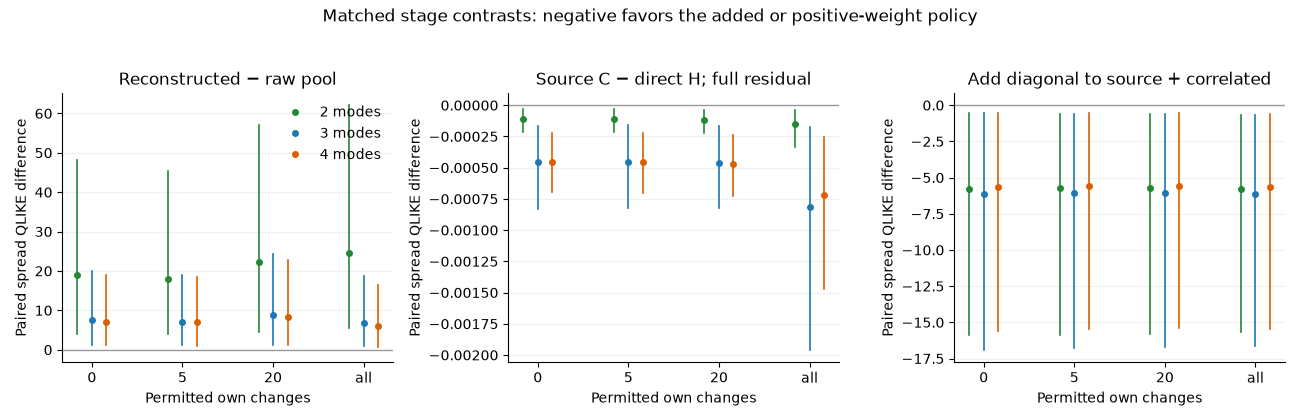

In [4]:
plot_stage_contrasts(evidence)
plt.show()
print(
    table(
        contrast_table(evidence, contrast="reconstruction_pool"),
        [
            ("dimension", "Modes"),
            ("budget", "Own history"),
            ("policy", "Fixed policy"),
            ("difference", "Score change"),
            ("range", "95% block range"),
            ("origins", "Paired origins"),
        ],
    )
)
print("Source-C minus direct-H with full residual repair:")
print(
    table(
        contrast_table(evidence, contrast="source_policy", policy="diagonal"),
        [
            ("dimension", "Modes"),
            ("budget", "Own history"),
            ("policy", "Fixed policy"),
            ("difference", "Score change"),
            ("range", "95% block range"),
            ("origins", "Paired origins"),
        ],
    )
)

## 3. Residual additions and their interactions

The correlated correction retains factor/residual cross terms through a Schur
decomposition. The diagonal correction uses truly donor-excluded predictive
errors and can include estimation and reconstruction error. It is not identified
latent noise. Compare column additions in both covariance rows and their
difference-in-differences; do not force an additive allocation of error.
These within-family contrasts do not telescope into the full SPDE/raw-pool gap:
historical maturity-slot mapping and own-history blending also differ from
evaluation at the current actual contracts' future maturities.

For the shared training blocks $(H,G,R)$, let $A=G^\top H^\dagger$ and
$\Omega=R-G^\top H^\dagger G$. The fully repaired price-change moment is
$$\widehat\Sigma=\delta\left[(B+\Psi A)H_f(B+\Psi A)^\top
+\Psi\Omega\Psi^\top+D\right].$$
The row chooses $H_f$; the other quantities stay fixed. The factor/residual
cross correction is signed, so it is not an independent positive risk source.

In [5]:
for contrast in (
    "residual_correlated",
    "residual_diagonal",
    "interaction_correlated",
    "interaction_diagonal",
):
    print(contrast)
    print(
        table(
            contrast_table(evidence, contrast=contrast),
            [
                ("dimension", "Modes"),
                ("budget", "Own history"),
                ("policy", "Fixed policy"),
                ("difference", "Score change"),
                ("range", "95% block range"),
                ("origins", "Paired origins"),
            ],
        )
    )

residual_correlated
| Modes | Own history | Fixed policy | Score change | 95% block range | Paired origins |
| --- | --- | --- | --- | --- | --- |
| 2 | 0 | empirical | -14.22 | [-35.15, -3.586] | 437 |
| 2 | 0 | source | -14.18 | [-35.06, -3.582] | 437 |
| 2 | 5 | empirical | -14.19 | [-35.07, -3.585] | 437 |
| 2 | 5 | source | -14.16 | [-34.98, -3.58] | 437 |
| 2 | 20 | empirical | -14.23 | [-35.16, -3.585] | 437 |
| 2 | 20 | source | -14.19 | [-35.07, -3.58] | 437 |
| 2 | all | empirical | -14.34 | [-35.44, -3.663] | 437 |
| 2 | all | source | -14.31 | [-35.35, -3.658] | 437 |
| 3 | 0 | empirical | -1.89 | [-4.584, -0.5142] | 437 |
| 3 | 0 | source | -1.906 | [-4.63, -0.5171] | 437 |
| 3 | 5 | empirical | -1.857 | [-4.487, -0.5122] | 437 |
| 3 | 5 | source | -1.873 | [-4.531, -0.5149] | 437 |
| 3 | 20 | empirical | -1.863 | [-4.514, -0.5214] | 437 |
| 3 | 20 | source | -1.879 | [-4.559, -0.5234] | 437 |
| 3 | all | empirical | -2.333 | [-5.783, -0.5892] | 437 |
| 3 | all | source | 

## 4. Calendar and interval-length controls

All-interval direct H mixes normalized covariances from unequal intervals. The
one-day control trains both policies on one-calendar-day intervals and compares
only one-day future outcomes. Other intervals retain their positions with zero
weights; no state gap is bridged and no EWMA age is compressed. The bootstrap
retains the master scheduled-origin calendar across all dimensions and budgets.
Annual strata are exploratory; repeated contracts and origins are dependent.

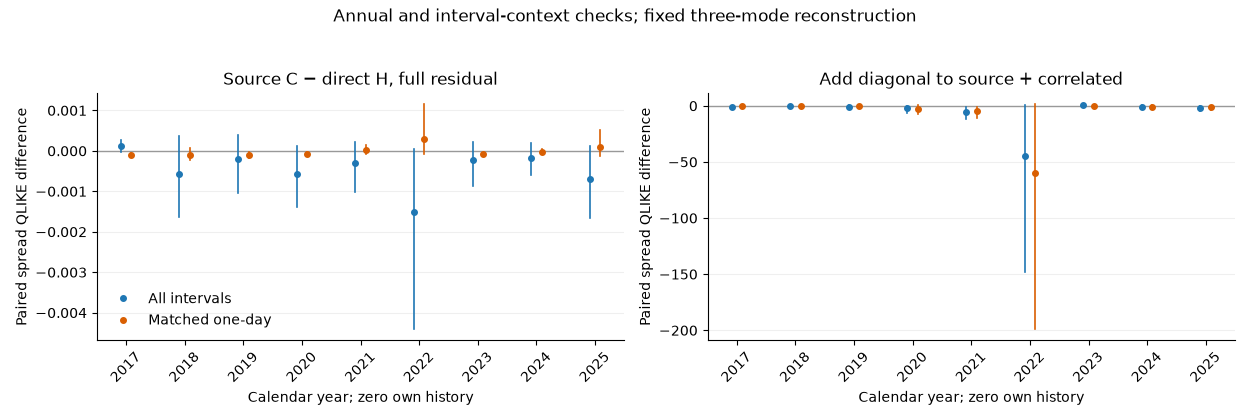

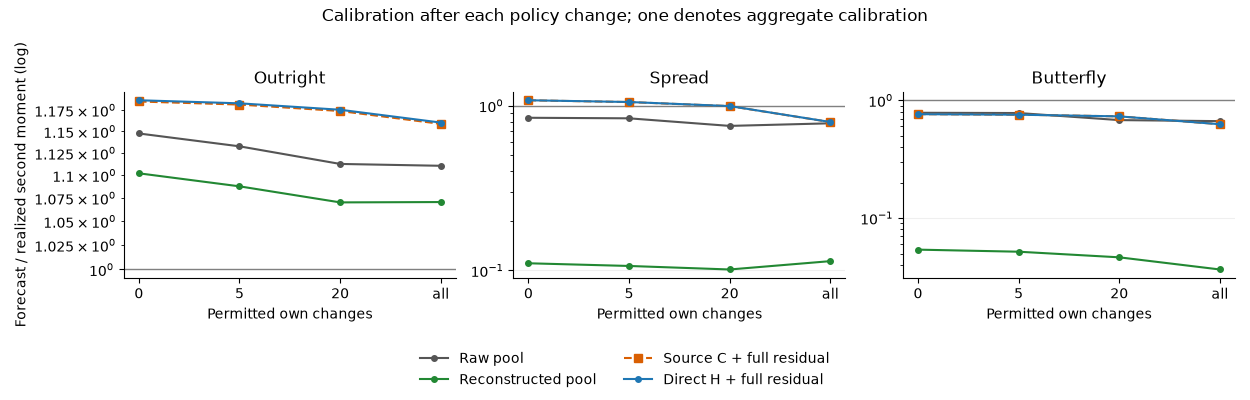

In [6]:
plot_calendar_context(evidence)
plt.show()
plot_calibration(evidence)
plt.show()

## 5. Synthetic controls with known truth

The transport control has known coefficients and C and reconstructs twelve-quote
spatial snapshots under fixed perturbation. The separate Gaussian increment
control has known correlated factor/residual blocks and verifies exact cross
terms. Its residuals are not asserted to arise from a level-consistent SPDE.
Synthetic MCSE uses independent replications; copper ranges use calendar blocks.

In [7]:
transport, residual = oracle_tables(evidence)
print(
    table(
        transport,
        [
            ("representation", "Coefficient input"),
            ("policy", "Covariance policy"),
            ("days", "Future days"),
            ("error", "Relative kernel error"),
            ("mcse", "Replication MCSE"),
        ],
    )
)
print(
    table(
        residual,
        [
            ("policy", "Known-block control"),
            ("error", "Relative kernel error"),
            ("spread_ratio", "Spread / truth"),
            ("butterfly_ratio", "Butterfly / truth"),
        ],
    )
)
assert evidence["oracle"]["residual"]["oracle_identity_relative_error"] < 1e-10
assert evidence["oracle"]["transport"]["maximum_relative_covariance_certificate"] <= 1e-5

| Coefficient input | Covariance policy | Future days | Relative kernel error | Replication MCSE |
| --- | --- | --- | --- | --- |
| known_coefficients | direct_H | 1 | 0.09613 | 0.01727 |
| known_coefficients | direct_H | 3 | 0.09619 | 0.01722 |
| known_coefficients | source_C | 1 | 0.09629 | 0.01721 |
| known_coefficients | source_C | 3 | 0.09624 | 0.01722 |
| reconstructed_coefficients | direct_H | 1 | 0.09619 | 0.01727 |
| reconstructed_coefficients | direct_H | 3 | 0.09624 | 0.01723 |
| reconstructed_coefficients | source_C | 1 | 0.09634 | 0.01721 |
| reconstructed_coefficients | source_C | 3 | 0.09629 | 0.01722 |
| Known-block control | Relative kernel error | Spread / truth | Butterfly / truth |
| --- | --- | --- | --- |
| oracle_full_joint | 4.479e-17 | 1 | 1 |
| oracle_omit_cross | 0.1074 | 1.082 | 0.9846 |
| oracle_factor_only | 0.1216 | 0.2063 | 0.005728 |
| oracle_no_diagonal | 0.002173 | 0.8625 | 0.885 |


## 6. Availability, numerical evidence and boundaries

Inspect source certificates, PSD/support checks, reconstruction leverage and
remaining residual dependence before ranking scores. Unavailable policies get
no fallback. Four residual features plus a diagonal remainder remain restrictive.
Held-out 2026 has not been used for protocol choices or model comparison. No
price prediction, derivative pricing or execution-cost result is established.

In [8]:
retention, numerical = diagnostic_tables(evidence)
print("Training reconstruction retention: ratios of mean window second moments; windows overlap.")
print(
    table(
        retention,
        [
            ("dimension", "Modes"),
            ("budget", "History"),
            ("exposure", "Exposure"),
            ("count", "Available windows"),
            ("retention", "Fitted/raw means"),
            ("residual", "Residual/raw means"),
            ("cross", "Signed cross/raw means"),
            ("identity", "Identity residual"),
        ],
    )
)
assert all(
    abs(row["retention"] + row["residual"] + row["cross"] - 1) < 1e-8
    for row in retention
    if all(row[key] is not None for key in ("retention", "residual", "cross"))
)
print(
    table(
        numerical,
        [
            ("dimension", "Modes"),
            ("context", "Intervals"),
            ("budget", "History"),
            ("certificate", "Max optimizer bound"),
            ("condition", "Curve condition"),
            ("leverage", "Level leverage"),
            ("support", "Support residual"),
            ("component", "Component residual"),
        ],
    )
)
availability = [
    {
        key: row[key]
        for key in (
            "context",
            "dimension",
            "method",
            "history_budget",
            "issued",
            "scored",
            "failures",
        )
    }
    for row in evidence["diagnostics"]["rows"]
]
print(
    table(
        availability,
        [
            ("context", "Intervals"),
            ("dimension", "Modes"),
            ("method", "Policy"),
            ("history_budget", "History"),
            ("issued", "Attempted"),
            ("scored", "Scored"),
            ("failures", "Unavailable reasons"),
        ],
    )
)
print("Cache audit:", evidence["diagnostics"]["cache"])
print("Recorded runtime seconds:", evidence["manifest"]["runtime_seconds"])
print("Numerical diagnostics are available in the checksummed diagnostics.json aggregate.")
assert (
    evidence["manifest"]["local_record_policy"]
    == "contract-level prices, forecasts and P&Ls are not exported"
)

Training reconstruction retention: ratios of mean window second moments; windows overlap.
| Modes | History | Exposure | Available windows | Fitted/raw means | Residual/raw means | Signed cross/raw means | Identity residual |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 2 | 0 | outright | 1311 | 0.9516 | 0.04168 | 0.006749 | 0 |
| 2 | 0 | spread | 1311 | 0.07409 | 0.9361 | -0.01019 | 0 |
| 2 | 0 | butterfly | 1311 | 0.002359 | 1.011 | -0.01289 | 0 |
| 2 | 5 | outright | 1311 | 0.9509 | 0.04269 | 0.006428 | 0 |
| 2 | 5 | spread | 1311 | 0.07145 | 0.9366 | -0.008013 | 0 |
| 2 | 5 | butterfly | 1311 | 0.001927 | 1.011 | -0.01317 | 0 |
| 2 | 20 | outright | 1311 | 0.955 | 0.03877 | 0.006193 | 0 |
| 2 | 20 | spread | 1311 | 0.07728 | 0.9214 | 0.001372 | 0 |
| 2 | 20 | butterfly | 1311 | 0.001793 | 1.012 | -0.01353 | 0 |
| 2 | all | outright | 1311 | 0.9563 | 0.04012 | 0.003621 | 0 |
| 2 | all | spread | 1311 | 0.06857 | 0.9146 | 0.01681 | 0 |
| 2 | all | butterfly | 1311 | 0.001497 |

## Reproduction

This notebook never opens market files. Run
`uv run python scripts/check_notebook.py notebooks/08_copper_mechanism_attribution.ipynb`.
The [report](../experiments/results/copper-mechanisms/report.md) gives local experiment
commands. Raw settlement panels, individual forecasts and P&Ls stay local;
public aggregates retain source, configuration, archive and environment hashes.
Historical evidence is preserved. The next confirmation requires frozen choices
before opening the held-out 2026 data.